# Assignment 4

Log transform, gamma transform and contrast stretching. c = 1.

Log and gamma use the dark lamp photo `sample_dark.jpg` (gamma = 0.5). Contrast stretch uses the flat Lena photo `sample_lena.png`: gray levels 100 to 177 are mapped to 15 to 240.


In [1]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt


# log, power law, and contrast stretching
# c = 1 for log and for gamma, as the question says

def log_transform(img):
    c = 1
    out = c * np.log1p(img.astype(np.float64))
    # c = 1 on 0-255 data only reaches about 5.5, so scale it for display
    out = cv2.normalize(out, None, 0, 255, cv2.NORM_MINMAX)
    return np.uint8(np.round(out))


def gamma_transform(img, gamma):
    c = 1
    norm = img.astype(np.float64) / 255.0
    out = c * np.power(norm, gamma)
    return np.clip(np.round(out * 255), 0, 255).astype(np.uint8)


def contrast_stretch(img, r1, s1, r2, s2):
    # piecewise linear
    # 0..r1   -> 0..s1
    # r1..r2  -> s1..s2
    # r2..255 -> s2..255
    r = img.astype(np.float64)
    out = np.zeros_like(r)

    low = r <= r1
    if r1 > 0:
        out[low] = (s1 / float(r1)) * r[low]
    else:
        out[low] = s1

    mid = (r > r1) & (r <= r2)
    out[mid] = s1 + (r[mid] - r1) * ((s2 - s1) / float(r2 - r1))

    high = r > r2
    if r2 < 255:
        out[high] = s2 + (r[high] - r2) * ((255.0 - s2) / float(255.0 - r2))
    else:
        out[high] = s2

    return np.clip(np.round(out), 0, 255).astype(np.uint8)


dark scene: sample_dark.jpg (427, 640)
low contrast: sample_lena.png (459, 466)
log transform with c = 1, then scaled to 0-255
gamma = 0.5 , c = 1
dark mean 45.32  log mean 150.61  gamma mean 93.64
intensity 100 maps to 15 , intensity 177 maps to 240
lena std 24.99  stretched std 65.48


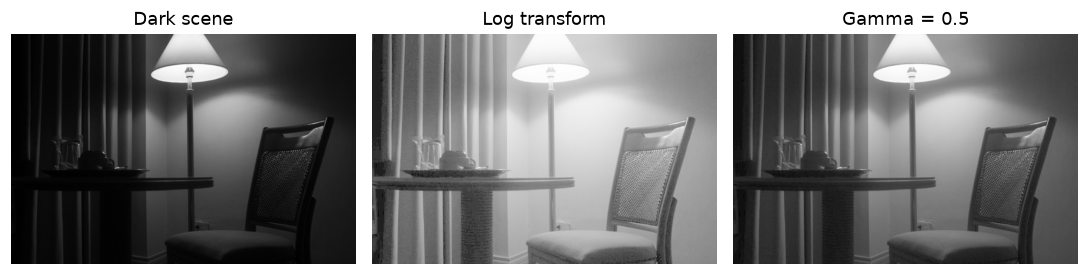

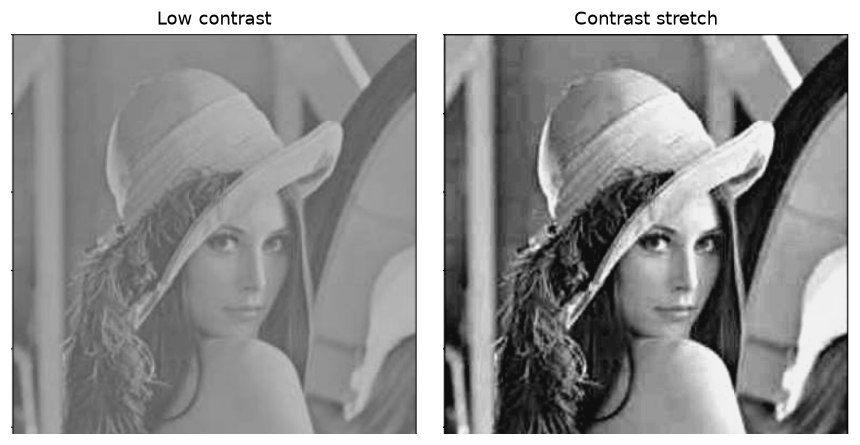

In [2]:
dark_path = "sample_dark.jpg"
lena_path = "sample_lena.png"
gamma = 0.5
r1, s1, r2, s2 = 100, 15, 177, 240

dark = cv2.imread(dark_path, 0)
lena = cv2.imread(lena_path, 0)
print("dark scene:", dark_path, dark.shape)
print("low contrast:", lena_path, lena.shape)

log_img = log_transform(dark)
gam_img = gamma_transform(dark, gamma)
con_img = contrast_stretch(lena, r1, s1, r2, s2)

print("log transform with c = 1, then scaled to 0-255")
print("gamma =", gamma, ", c = 1")
print("dark mean", round(float(dark.mean()), 2),
      " log mean", round(float(log_img.mean()), 2),
      " gamma mean", round(float(gam_img.mean()), 2))
print("intensity", r1, "maps to", s1, ", intensity", r2, "maps to", s2)
print("lena std", round(float(lena.std()), 2), " stretched std", round(float(con_img.std()), 2))

plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(dark, cmap="gray", vmin=0, vmax=255)
plt.title("Dark scene")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(log_img, cmap="gray", vmin=0, vmax=255)
plt.title("Log transform")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(gam_img, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma = " + str(gamma))
plt.axis("off")
plt.tight_layout()

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(lena, cmap="gray", vmin=0, vmax=255)
plt.title("Low contrast")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(con_img, cmap="gray", vmin=0, vmax=255)
plt.title("Contrast stretch")
plt.axis("off")
plt.tight_layout()
plt.show()
